In [1]:
import pandas as pd
import numpy as np
import random
import tensorflow as tf

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import PassiveAggressiveClassifier

from sklearn.utils import shuffle
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.metrics import roc_curve, auc
import joblib

from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense, Concatenate
from tensorflow.keras.utils import to_categorical

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

# import os
# os.environ['TF_CPP_MIN_LOG_LEVEL'] = ''


Dataset Link: https://www.kaggle.com/datasets/01a9c71a93d56cf3beec9a5436c7d02ef66df3259fdb483a4864b803ea3ced6b


# Robust Text Classification: SMS Spam Collection, Spam and Ham Classification, SpamAssassin

**Spam-mails Dataset**

In [2]:


pd.set_option('display.max_colwidth', 300)

# NEWS Dataset CSV file path
df_mail = pd.read_csv('/kaggle/input/datasets/shafiqulbashar/spam-mails-dataset/spam_ham_dataset.csv')


# Check structure
df_mail.head()

,Unnamed: 0,label,text,label_num
0,605,ham,"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis chang...",0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 . xls",0
2,3624,ham,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time !\r\ni know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 t...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fortuitous undergone\r\nlighthearted charm orinoco taster\r\nrailroad affluent pornographic cuvier\r\nirvin parkhouse blameworthy chlorophyll\r\nrobed diagrammatic fogarty clears bayda\r\ninconveniencing ...",1
4,2030,ham,"Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understanding that teco\r\njust sends us a check , i haven ' t received an answer as to whether there is a\r\npredermined price associated with this deal or if teco just lets us know what\r\nwe are giving . i ca...",0


In [3]:


# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_mail['label'].value_counts(),
    'Percentage': (df_mail['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
ham     3672       71.01
spam    1499       28.99


In [4]:

#Dropping columns that are not needed
df_mail = df_mail.drop('Unnamed: 0', axis=1)
df_mail = df_mail.drop('label', axis=1)

# rename label_num
df_mail.rename(columns={'label_num': 'label'}, inplace=True)

# Check structure
df_mail.head()

,text,label
0,"Subject: enron methanol ; meter # : 988291\r\nthis is a follow up to the note i gave you on monday , 4 / 3 / 00 { preliminary\r\nflow data provided by daren } .\r\nplease override pop ' s daily volume { presently zero } to reflect daily\r\nactivity you can obtain from gas control .\r\nthis chang...",0
1,"Subject: hpl nom for january 9 , 2001\r\n( see attached file : hplnol 09 . xls )\r\n- hplnol 09 . xls",0
2,"Subject: neon retreat\r\nho ho ho , we ' re around to that most wonderful time of the year - - - neon leaders retreat time !\r\ni know that this time of year is extremely hectic , and that it ' s tough to think about anything past the holidays , but life does go on past the week of december 25 t...",0
3,"Subject: photoshop , windows , office . cheap . main trending\r\nabasements darer prudently fortuitous undergone\r\nlighthearted charm orinoco taster\r\nrailroad affluent pornographic cuvier\r\nirvin parkhouse blameworthy chlorophyll\r\nrobed diagrammatic fogarty clears bayda\r\ninconveniencing ...",1
4,"Subject: re : indian springs\r\nthis deal is to book the teco pvr revenue . it is my understanding that teco\r\njust sends us a check , i haven ' t received an answer as to whether there is a\r\npredermined price associated with this deal or if teco just lets us know what\r\nwe are giving . i ca...",0


**SMS-spam-collection-dataset**

In [5]:

# Replace with your actual CSV file path
df_sms = pd.read_csv('/kaggle/input/datasets/shafiqulbashar/sms-spam-collection-dataset/spam.csv',
                 encoding="latin-1", encoding_errors="replace")


# Check structure
df_sms.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


In [6]:

#Dropping columns that are not needed
df_sms = df_sms.drop('Unnamed: 2', axis=1)
df_sms = df_sms.drop('Unnamed: 3', axis=1)
df_sms = df_sms.drop('Unnamed: 4', axis=1)

# rename label_num
df_sms.rename(columns={'v1': 'label'}, inplace=True)
df_sms.rename(columns={'v2': 'text'}, inplace=True)

# Check structure
df_sms.head()


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [7]:

# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_sms['label'].value_counts(),
    'Percentage': (df_sms['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
ham     4825       86.59
spam     747       13.41


In [8]:

#Swapping the dataframe columns 
df_sms = df_sms[['text', 'label']]

if df_sms['label'].dtype == object:
    df_sms['label'] = df_sms['label'].str.upper().map({'HAM': 0, 'SPAM': 1})

df_sms.head()

,text,label
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,Ok lar... Joking wif u oni...,0
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives around here though",0


**Spam and Ham Classification SpamAssassin**

In [9]:

# Replace with your actual CSV file path
df_spam = pd.read_csv('/kaggle/input/datasets/bayes2003/emails-for-spam-or-ham-classification-spamassassin/email_text.csv',
                 encoding="latin-1", encoding_errors="replace")


# Check structure
df_spam.head()

,label,text
0,0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...
1,0,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...
2,0,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...
3,0,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism an...
4,0,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...


In [10]:

# Class Distribution: Count and Percentage
class_distribution = pd.DataFrame({
    'Count': df_spam['label'].value_counts(),
    'Percentage': (df_spam['label'].value_counts(normalize=True) * 100).round(2)
})

print(class_distribution)

       Count  Percentage
label                   
0       4072        72.2
1       1568        27.8


In [11]:


#Swapping the dataframe columns 
df_spam = df_spam[['text', 'label']]

# if df_spam['label'].dtype == object:
#     df_spam['label'] = df_spam['label'].str.upper().map({'HAM': 0, 'SPAM': 1})

df_spam.head()

,text,label
0,me spam is the tool for dissident news since the fact that it's unsolicited means that recipients can't be blamed for being on a mailing list russell turpin that depends on how the list is collected or even on what the senders say about how the list is collected better to just put it on a websit...,0
1,escapenumber escapenumber escapenumber penguinreport career services from lockergnome and dice com we've teamed up with dice com to bring you a full service i t career enhancement solution whether you are looking for your dream job or trying to hire talented people the full featured career resou...,0
2,on wednesday escapenumber july escapenumber escapenumber escapenumber satelle stevenx wrote its nothing to do with irish it was the way it was tought in primary i was made to stand up in front of the class and name all the items on a projector screen my teacher knew that i didnt even know what h...,0
3,can't think of how i'd be running afoul of the spam filters with this post so here's the second try kissinger's book does america need a foreign policy provides a few handy abstractions the ultimate dilemma of the statesman is to strike a balance between values idealism and interests realism an...,0
4,forwarded by william knowles http www thesun co uk article escapenumber escapenumber escapenumber escapenumber html by paul crosbie sep escapenumber escapenumber virgin's latest airliner is being revamped after randy passengers discovered a tiny cabin was just the place to join the mile high clu...,0


# **Pre-Processing**

# Combine Dataset

In [15]:
# Combining Dataset

# Add domain identifiers
# df_mail['domain'] = 'news'
# df_sms['domain'] = 'sms'
# df_spam['domain'] = 'email'
# df_health['domain'] = 'health'

# Assisgn Test
df_test = df_sms.copy() #df_mail

# Combine source domains
df_combine = pd.concat(
    [df_mail, df_spam, ], #  df_spam 
)

print("Combined source training data:")
print(df_combine.shape)

print("\nClass distribution:")
print(df_combine['label'].value_counts())

print("\nClass distribution (%):")
print((df_combine['label'].value_counts(normalize=True) * 100).round(2))



Combined source training data:
(10811, 2)

Class distribution:
label
0    7744
1    3067
Name: count, dtype: int64

Class distribution (%):
label
0    71.63
1    28.37
Name: proportion, dtype: float64


In [16]:
# Shuffle
df_combine = df_combine.sample(frac=1, random_state=42).reset_index(drop=True)

df_combine

,text,label
0,Subject: oxyyyyconttin no script needeeed\r\n{ taaabbsittabbs } { cccheaapicheeep }\r\n{ ssstttoooppp hhhhurting todayistop da pain now }\r\nhttp : / / offfmeebabyy\r\n,1
1,sm skip montanaro writes jeremy put another way i'd be interested to hear why you don't jeremy want to use zodb sm disclaimer i'm not saying i don't want to use zodb i'm sm offering some reasons why it might not be everyone's obvious sm choice but you're not saying you do want to use zodb so yo...,0
2,take yourself out of our list by clicking here bored with your cell phone Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â get cool songs logos to your phone today Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â Â it's real simple no confusing downloads or instal...,1
3,u udhay shankar n writes u at escapenumber escapenumber pm escapenumber escapenumber escapenumber escapenumber adam rifkin wrote i repeat ibm escapenumber escapenumbergb ultra dma escapenumber hard drive at fry's for escapenumber home of fast friendly courteous service r u less than two years l...,0
4,problem with spamtrap home yyyy lib spamtrap sh home yyyy ftp spamassassin spamassassin no such file or directory,0
...,...,...
10806,i gota thank all you kind folk who sent thier well wishes our way it was a bumpy ride but everything is working out and allthe good vibes are a tremendous help ive saved each one and along with the cards and other emails we have been getting we are goign to print them out add them to benjamins b...,0
10807,once upon a time julian wrote one of the things you need to understand with gnomeescapenumber is that while they did simplify a lot of things most of the configuration options people found very useful are still available through gconf learn to love gconf editor metacity can have sloppy focus des...,0
10808,url http www newsisfree com click escapenumber escapenumber escapenumber date not supplied us officials have all but confirmed that the virus which has killed escapenumber people can be transmitted via donated blood,0
10809,"Subject: re : meter 1459 , 6 / 00\r\nyep , you ' re right , except it ' s out there for june 1999 . please let me know .\r\ni ' ll be out tomorrow , if you get this done then , let carlos know and he can\r\nget it set up in pops .\r\naimee\r\ndaren j farmer\r\n07 / 13 / 2000 01 : 16 pm\r\nto : a...",0


In [17]:

df_test.head()

,text,label
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,Ok lar... Joking wif u oni...,0
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,1
3,U dun say so early hor... U c already then say...,0
4,"Nah I don't think he goes to usf, he lives around here though",0


In [14]:

print("TRAIN labels:")
print(df_combine['label'].value_counts())
print(df_combine['label'].value_counts(normalize=True))

print("\nTEST labels:")
print(df_test['label'].value_counts())
print(df_test['label'].value_counts(normalize=True))

print("\nUnique labels:")
print("Train:", df_combine['label'].unique())
print("Test :", df_test['label'].unique())

TRAIN labels:
label
0    7744
1    3067
Name: count, dtype: int64
label
0    0.716307
1    0.283693
Name: proportion, dtype: float64

TEST labels:
label
0    4825
1     747
Name: count, dtype: int64
label
0    0.865937
1    0.134063
Name: proportion, dtype: float64

Unique labels:
Train: [1 0]
Test : [0 1]


# **Clean Text**

In [18]:
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords


[nltk_data] Downloading package stopwords to /usr/share/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [19]:
# Function creation for data cleanup, data manipulation and removal of stopwords
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

import re

STOPWORDS = set(stopwords.words('english'))
STOPWORDS.remove('not') #removing not from the stop words
lemmatizer = WordNetLemmatizer()

# def clean_text(text):
#     text = text.lower() # lowercase text
#     text = ' '.join(word for word in text.split() if word not in STOPWORDS) # remove stopwords from text
#     # text = re.sub(r'\b(clinton|trump|hillary|obama|said)\b', '', text)

#     text = re.sub(r'\W', ' ', text) # Remove all the special characters
#     text = re.sub(r'\d+', '', text) # remove numerical values not for Health related DS
#     text = re.sub(r'<.*?>', '', text) # remove HTML tags
#     text = re.sub(r'http\S+', '', text) # remove URLs
#     text = re.sub(r'(?i)\bsubject\s*:?\s*', '', text)  # Remove "Subject" or "Subject:" (case-insensitive)
#     text = re.sub(r'\s+[a-zA-Z]\s+', ' ', text)  # remove all single characters
#     text = re.sub(r'\^[a-zA-Z]\s+', ' ', text) # Remove single characters from the start
#     text = re.sub(r'\s+', ' ', text, flags=re.I) # Substituting multiple spaces with single space
#     text = re.sub(r'(?:Â\s*)+', ' ', text)
#     text = ' '.join(lemmatizer.lemmatize(word) for word in text.split()) # perform lemmatization to get the root of english words
#     return text

# def clean_text(text):
#     if not isinstance(text, str):
#         text = str(text)

#     text = text.lower()

#     # Preserve useful structural information
#     text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
#     text = re.sub(r'\S+@\S+', ' EMAIL ', text)
#     text = re.sub(r'(?:â\s*)+', ' ', text)

#     # HTML tags
#     text = re.sub(r'<[^>]+>', ' ', text)

#     # Normalize whitespace only
#     text = re.sub(r'\s+', ' ', text).strip()    

#     return text
    
# def clean_text(text):
#     if not isinstance(text, str):
#         text = str(text)

#     text = text.lower()
      
#     text = re.sub(r'<[^>]+>', ' ', text)                          # HTML first
#     text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)        # then URLs
#     text = re.sub(r'\S+@\S+', ' EMAIL ', text)                    # then emails
#     text = re.sub(r'^\s*subject\s*:?\s*', '', text)
#     text = re.sub(r'[£€¥$]', ' CURRENCY ', text)
#     text = re.sub(r'[^\x00-\x7F]+', ' ', text)  # now only catches true encoding artifacts
#     text = re.sub(r'escapenumber', ' NUM ', text, flags=re.IGNORECASE)
#     text = re.sub(r'\d+', ' NUM ', text)
#     text = re.sub(r'(NUM[\s/:\-,.]*)+', 'NUM ', text)
    
#     text = re.sub(r'\s+', ' ', text).strip()
#     return text

def clean_text(text):
    if not isinstance(text, str):
        text = str(text)
        
    # Convert to lowercase
    text = text.lower()
    
    # Replace URLs with a token
    text = re.sub(r'http\S+|www\S+', ' URL ', text)
    
    # Replace email addresses with a token
    text = re.sub(r'\S+@\S+', ' EMAIL ', text)
    
    # Remove HTML tags
    text = re.sub(r'<.*?>', ' ', text)
    
    # Optional: Normalize prolonged characters (e.g., "freeeeee" -> "free")
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    
    # Clean up extra whitespace and trim
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

In [20]:
#Function testing
print(clean_text('Viral Dubai chocolate  craze!!! drives   pistachio costs \n up by Dh10 per kg in two months; Not Cheap(!)'))

viral dubai chocolate craze!! drives pistachio costs up by dh10 per kg in two months; not cheap(!)


In [21]:

#Apply Text Cleaning to text---
df_combine['text'] = df_combine['text'].apply(clean_text)

df_combine['text'].count()

np.int64(10811)

In [22]:


#Apply Text Cleaning to Test---
df_test['text'] = df_test['text'].apply(clean_text)

df_test['text'].count()

np.int64(5572)

In [22]:
# Training Set
df_combine.head()

,text,label
0,oxyyyyconttin no script needeeed { taaabbsittabbs } { cccheaapicheeep } { ssstttoooppp hhhhurting todayistop da pain now } http : / / offfmeebabyy,1
1,sm skip montanaro writes jeremy put another way i'd be interested to hear why you don't jeremy want to use zodb sm disclaimer i'm not saying i don't want to use zodb i'm sm offering some reasons why it might not be everyone's obvious sm choice but you're not saying you do want to use zodb so you...,0
2,take yourself out of our list by clicking here bored with your cell phone get cool songs logos to your phone today it's real simple no confusing downloads or installations simple phone activation click here to order there are tons of songs and graphics to choose from see a sample of some of the ...,1
3,u udhay shankar n writes u at NUM pm NUM adam rifkin wrote i repeat ibm NUM gb ultra dma NUM hard drive at fry's for NUM home of fast friendly courteous service r u less than two years later we have NUM gb for the same price so then why does my webhost still only give me NUM mb gary lawrence mur...,0
4,problem with spamtrap home yyyy lib spamtrap sh home yyyy ftp spamassassin spamassassin no such file or directory,0


In [23]:
df_test.head()

,text,label
0,"go until jurong point, crazy.. available only in bugis n great world la e buffet... cine there got amore wat...",0
1,ok lar... joking wif u oni...,0
2,free entry in NUM a wkly comp to win fa cup final tkts NUM st may NUM text fa to NUM to receive entry question(std txt rate)t&c's apply NUM over NUM 's,1
3,u dun say so early hor... u c already then say...,0
4,"nah i don't think he goes to usf, he lives around here though",0


# Exploratory Data Analysis

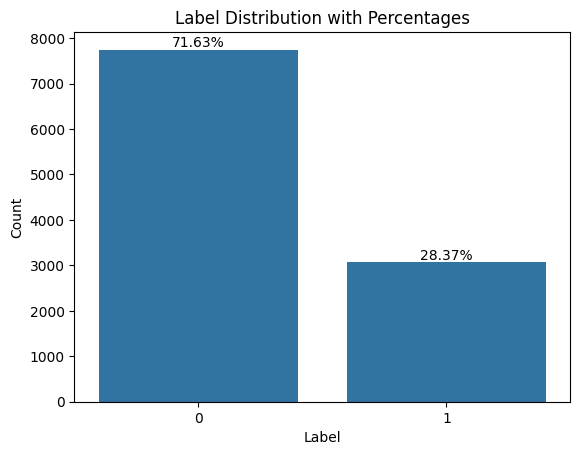

In [25]:


# Dataset Distribution

# Create count plot
ax = sns.countplot(x=df_combine.label)

# Get total number of samples
total = len(df_combine.label)

# Annotate percentages on bars
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.2f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom')

# Add title and labels
plt.title('Label Distribution with Percentages')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

In [26]:


# Word Count for news text

# Word Count
total_words = df_combine['text'].apply(lambda x: len(x.split())).sum()

# Character Count
total_characters = df_combine['text'].apply(len).sum()

# Sentence Count
total_sentences = df_combine['text'].apply(lambda x: len(sent_tokenize(x))).sum()

print(f"Word count for email: {total_words:,}")
print(f"Character count: {total_characters:,}")
print(f"Sentence count: {total_sentences:,}")

Word count for email: 2,940,936
Character count: 16,453,487
Sentence count: 73,490


**Word Map**

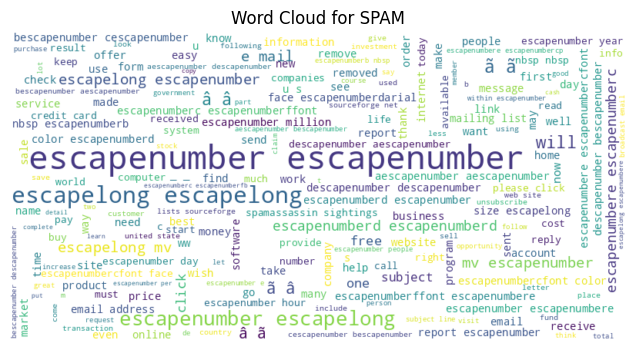

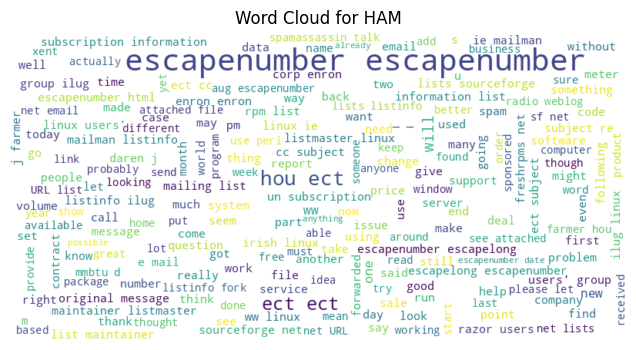

In [24]:


from wordcloud import WordCloud, STOPWORDS

stopwords = set(STOPWORDS)

# Create combined string for each class:  'FAKE': 1, 'REAL': 0
spam_text = " ".join(df_combine[df_combine['label'] == 1]['text'].tolist())
ham_text = " ".join(df_combine[df_combine['label'] == 0]['text'].tolist())

# Create WordClouds
fake_wc = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords).generate(spam_text)
real_wc = WordCloud(width=800, height=400, background_color='white', stopwords=stopwords).generate(ham_text)

# Plot Fake News Word Cloud
plt.figure(figsize=(8,4))
plt.imshow(fake_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for SPAM")
plt.show()

# Plot Real News Word Cloud
plt.figure(figsize=(8, 4))
plt.imshow(real_wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud for HAM")
plt.show()

# **Parameterized Pipeline**

In [38]:


# Parametirized pipeline
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import optuna


# ============================================================
# 1. Select input features
# ============================================================

X_train = df_combine[['text']]
X_test = df_test[['text']]

y_train = df_combine[['label']]
y_test = df_test[['label']]


# Convert label DataFrames to 1D arrays
y_train = y_train.values.ravel()
y_test = y_test.values.ravel()


# ============================================================
# 2. Parameterized preprocessing pipeline
# ============================================================

def get_preprocessing_pipeline(
    max_features=None,
    vectorizer_type='tfidf',
    ngram_min=1,
    ngram_max=2,
    min_df=1
):

    # Select vectorizer
    if vectorizer_type == 'count':

        vectorizer = CountVectorizer(
            analyzer='char_wb',
            max_features=max_features,
            ngram_range=(ngram_min, ngram_max),
            min_df=min_df,
            max_df=1.0
        )

    elif vectorizer_type == 'tfidf':

        vectorizer = TfidfVectorizer(
            analyzer='char',
            max_features=max_features,
            ngram_range=(ngram_min, ngram_max),
            min_df=min_df,
            max_df=1.0
        )

    else:
        raise ValueError(
            "vectorizer_type must be either 'count' or 'tfidf'"
        )

    # Pipeline
    pipeline = Pipeline([
        ('vectorizer', vectorizer)
    ])

    return pipeline

# **Logistic Regression**

In [51]:


## Hyper Parameter Tuning for Logistic regression
import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. Logistic Regression hyperparameters
    # --------------------------------------------------------

    C = trial.suggest_float(
        "C",
        1e-3,
        10.0,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    solver = trial.suggest_categorical(
        "solver",
        ["liblinear", "saga"]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        ["count", "tfidf"]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_lr = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_lr.fit_transform(
        X_train['text']
    )

    X_test_transformed = pipeline_lr.transform(
        X_test['text']
    )


    # --------------------------------------------------------
    # 6. Logistic Regression model
    # --------------------------------------------------------

    model = LogisticRegression(
        C=C,
        penalty="l2",
        solver=solver,
        class_weight="balanced",
        max_iter=max_iter,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-18 03:15:29,348] A new study created in memory with name: no-name-eb6683f8-f4f1-4cf0-9013-a37b3cb0f606
[I 2026-09-18 03:15:48,295] Trial 0 finished with value: 0.5692749461593682 and parameters: {'C': 0.047626459361584134, 'max_iter': 232, 'solver': 'saga', 'vectorizer_type': 'tfidf', 'max_features': 368881, 'ngram_min': 2, 'ngram_max': 3, 'min_df': 3}. Best is trial 0 with value: 0.5692749461593682.
[I 2026-09-18 03:18:09,561] Trial 1 finished with value: 0.44221105527638194 and parameters: {'C': 1.1117707655244822, 'max_iter': 337, 'solver': 'saga', 'vectorizer_type': 'count', 'max_features': 249720, 'ngram_min': 1, 'ngram_max': 4, 'min_df': 4}. Best is trial 0 with value: 0.5692749461593682.
[I 2026-09-18 03:26:17,919] Trial 2 finished with value: 0.5143575017946878 and parameters: {'C': 5.476930584645299, 'max_iter': 1889, 'solver': 'liblinear', 'vectorizer_type': 'count', 'max_features': 384056, 'ngram_min': 3, 'ngram_max': 6, 'min_df': 4}. Best is trial 0 with value: 0


Best Trial:
Accuracy: 0.8034816941852118

Best Parameters:
  C: 0.0011930143461265402
  max_iter: 1468
  solver: saga
  vectorizer_type: tfidf
  max_features: 491671
  ngram_min: 1
  ngram_max: 6
  min_df: 3


In [58]:

# ============================================================
# Logistic Regression
# Best Optuna Parameters
# ============================================================

best_C = 0.0011930143461265402
best_max_iter = 1468
best_solver = "saga"
best_class_weight = "balanced"

best_vectorizer_type = "tfidf"
best_max_features = 491671
best_ngram_min = 1
best_ngram_max = 6
best_min_df = 3


# ============================================================
# Parameterized Character-Level Preprocessing Pipeline
# analyzer='char' remains fixed inside the function
# ============================================================

pipeline_lr = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# ============================================================
# Transform Text
# ============================================================

X_train_transformed = pipeline_lr.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_lr.transform(
    X_test["text"]
)


# ============================================================
# Final Logistic Regression Model
# ============================================================

modelLR = LogisticRegression(
    C=best_C,
    penalty="l2",
    solver=best_solver,
    class_weight=best_class_weight,
    max_iter=best_max_iter,
    random_state=42
)


# ============================================================
# Train
# ============================================================

modelLR.fit(
    X_train_transformed,
    y_train
)


# ============================================================
# Prediction
# ============================================================

y_pred = modelLR.predict(
    X_test_transformed
)


# ============================================================
# Evaluation
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
    
) 


# ============================================================
# Results
# ============================================================

print("Logistic Regression")
print("Accuracy:", accuracy)
print("Macro F1:", f1)


# ============================================================
# Classification Report
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred
    )
)

Logistic Regression
Accuracy: 0.8034816941852118
Macro F1: 0.5440628158399639

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.90      0.89      4825
           1       0.22      0.18      0.20       747

    accuracy                           0.80      5572
   macro avg       0.55      0.54      0.54      5572
weighted avg       0.79      0.80      0.80      5572



# **Linear SVC**

In [39]:

import optuna

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score


# ============================================================
# Focused Hyperparameter Tuning for LinearSVC
# Character TF-IDF fixed based on baseline
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # LinearSVC hyperparameters
    # --------------------------------------------------------

    C = trial.suggest_float(
        "C",
        1e-2,
        10.0,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        1000,
        10000,
        step=500
    )

    loss = trial.suggest_categorical(
        "loss",
        ["hinge", "squared_hinge"]
    )


    # --------------------------------------------------------
    # Fixed class weighting
    # --------------------------------------------------------

    class_weight = "balanced"


    # --------------------------------------------------------
    # Fixed character TF-IDF
    # --------------------------------------------------------

    pipeline_svc = get_preprocessing_pipeline(
        max_features=None,
        vectorizer_type="tfidf",
        ngram_min=3,
        ngram_max=7,
        min_df=2
    )


    # --------------------------------------------------------
    # Transform data
    # --------------------------------------------------------

    X_train_transformed = pipeline_svc.fit_transform(
        X_train["text"]
    )

    X_test_transformed = pipeline_svc.transform(
        X_test["text"]
    )


    # --------------------------------------------------------
    # LinearSVC
    # --------------------------------------------------------

    model = LinearSVC(
        C=C,
        loss=loss,
        class_weight=class_weight,
        max_iter=max_iter,
        random_state=42
    )


    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # Predict
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    return accuracy_score(
        y_test,
        y_pred
    )


# ============================================================
# Run Optuna
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

print("\nFixed Parameters:")
print("  class_weight: balanced")
print("  vectorizer_type: tfidf")
print("  analyzer: char")
print("  ngram_range: (3, 7)")
print("  min_df: 2")

[I 2026-09-19 02:56:21,020] A new study created in memory with name: no-name-df6ca9c6-a024-4233-ba9f-b6b28f28cce0
[I 2026-09-19 02:57:59,084] Trial 0 finished with value: 0.708183776022972 and parameters: {'C': 0.37757260863804293, 'max_iter': 2000, 'loss': 'squared_hinge'}. Best is trial 0 with value: 0.708183776022972.
[I 2026-09-19 02:59:36,265] Trial 1 finished with value: 0.7207465900933238 and parameters: {'C': 0.6221855582871255, 'max_iter': 5000, 'loss': 'squared_hinge'}. Best is trial 1 with value: 0.7207465900933238.
[I 2026-09-19 03:01:51,291] Trial 2 finished with value: 0.5550969131371142 and parameters: {'C': 0.09930161718937225, 'max_iter': 9000, 'loss': 'hinge'}. Best is trial 1 with value: 0.7207465900933238.
[I 2026-09-19 03:03:22,168] Trial 3 finished with value: 0.6500358937544867 and parameters: {'C': 0.10181774686942577, 'max_iter': 3500, 'loss': 'squared_hinge'}. Best is trial 1 with value: 0.7207465900933238.
[I 2026-09-19 03:04:58,002] Trial 4 finished with val


Best Trial:
Accuracy: 0.7656137832017229

Best Parameters:
  C: 1.5230785599087782
  max_iter: 4500
  loss: hinge

Fixed Parameters:
  class_weight: balanced
  vectorizer_type: tfidf
  analyzer: char
  ngram_range: (3, 7)
  min_df: 2


In [73]:



## Hyper Parameter Tuning for LinearSVC

import optuna
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. LinearSVC hyperparameters
    # --------------------------------------------------------

    C = trial.suggest_float(
        "C",
        1e-3,
        1.0,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        2000
    )

    loss = trial.suggest_categorical(
        "loss",
        ["hinge", "squared_hinge"]
    )

    class_weight = trial.suggest_categorical(
        "class_weight",
        ["balanced"]
    )


    # --------------------------------------------------------
    # 2. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        ["count", "tfidf"]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 3. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 4. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_svc = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 5. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_svc.fit_transform(
        X_train["text"]
    )

    X_test_transformed = pipeline_svc.transform(
        X_test["text"]
    )


    # --------------------------------------------------------
    # 6. LinearSVC model
    # --------------------------------------------------------

    model = LinearSVC(
        C=C,
        loss=loss,
        class_weight=class_weight,
        max_iter=max_iter,
        random_state=42
    )


    # --------------------------------------------------------
    # 7. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 8. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 9. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study.best_value)

print("\nBest Parameters:")

for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-18 16:51:40,613] A new study created in memory with name: no-name-02f10498-03d7-4d19-b656-b7f2d61767e3
[I 2026-09-18 16:52:15,217] Trial 0 finished with value: 0.5357142857142857 and parameters: {'C': 0.05130454592630835, 'max_iter': 1834, 'loss': 'squared_hinge', 'class_weight': 'balanced', 'vectorizer_type': 'tfidf', 'max_features': 408645, 'ngram_min': 1, 'ngram_max': 4, 'min_df': 3}. Best is trial 0 with value: 0.5357142857142857.
[I 2026-09-18 16:53:40,736] Trial 1 finished with value: 0.659727207465901 and parameters: {'C': 0.3105329962735968, 'max_iter': 1564, 'loss': 'hinge', 'class_weight': 'balanced', 'vectorizer_type': 'tfidf', 'max_features': 421522, 'ngram_min': 4, 'ngram_max': 6, 'min_df': 4}. Best is trial 1 with value: 0.659727207465901.
[I 2026-09-18 16:54:44,832] Trial 2 finished with value: 0.5703517587939698 and parameters: {'C': 0.001013222948409084, 'max_iter': 408, 'loss': 'squared_hinge', 'class_weight': 'balanced', 'vectorizer_type': 'tfidf', 'max_fe


Best Trial:
Accuracy: 0.7449748743718593

Best Parameters:
  C: 0.9032355265289546
  max_iter: 1314
  loss: hinge
  class_weight: balanced
  vectorizer_type: tfidf
  max_features: 323729
  ngram_min: 3
  ngram_max: 6
  min_df: 2


In [69]:

# ============================================================
# LinearSVC
# Best Optuna Parameters
# ============================================================

best_C = 4.401978177580566
best_max_iter = 1564
best_loss = "squared_hinge"
best_class_weight = "balanced"

best_vectorizer_type = "tfidf"
best_max_features = 411677
best_ngram_min = 5
best_ngram_max = 6
best_min_df = 3


# ============================================================
# Character-Level Preprocessing Pipeline
# analyzer='char' is fixed inside the function
# ============================================================

pipeline_svc = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# ============================================================
# Transform Text
# ============================================================

X_train_transformed = pipeline_svc.fit_transform(
    X_train["text"]
)

X_test_transformed = pipeline_svc.transform(
    X_test["text"]
)


# ============================================================
# Final LinearSVC Model
# ============================================================

modelSVC = LinearSVC(
    C=best_C,
    loss=best_loss,
    class_weight=best_class_weight,
    max_iter=best_max_iter,
    random_state=42
)


# ============================================================
# Train
# ============================================================

modelSVC.fit(
    X_train_transformed,
    y_train
)


# ============================================================
# Prediction
# ============================================================

y_pred = modelSVC.predict(
    X_test_transformed
)


# ============================================================
# Evaluation
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)


# ============================================================
# Results
# ============================================================

print("LinearSVC")
print("Accuracy:", accuracy)
print("Macro F1:", f1)


# ============================================================
# Classification Report
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)


# ============================================================
# Confusion Matrix
# ============================================================

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred
    )
)


# ============================================================
# Prediction Distribution
# ============================================================

print("\nActual Test Distribution:")
print(
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)

print("\nPredicted Test Distribution:")
print(
    pd.Series(y_pred)
    .value_counts()
    .sort_index()
)

LinearSVC
Accuracy: 0.756640344580043
Macro F1: 0.6256542946222392

Classification Report:
              precision    recall  f1-score   support

           0     0.9290    0.7784    0.8471      4825
           1     0.3009    0.6158    0.4042       747

    accuracy                         0.7566      5572
   macro avg     0.6149    0.6971    0.6257      5572
weighted avg     0.8448    0.7566    0.7877      5572


Confusion Matrix:
[[3756 1069]
 [ 287  460]]

Actual Test Distribution:
0    4825
1     747
Name: count, dtype: int64

Predicted Test Distribution:
0    4043
1    1529
Name: count, dtype: int64


# **SGD Classifier**

In [71]:
## Hyper Parameter Tuning for SGD Classifier

import optuna
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score


# ============================================================
# Optuna Objective Function
# ============================================================

def objective(trial):

    # --------------------------------------------------------
    # 1. SGD Classifier hyperparameters
    # --------------------------------------------------------

    alpha = trial.suggest_float(
        "alpha",
        1e-6,
        1e-1,
        log=True
    )

    max_iter = trial.suggest_int(
        "max_iter",
        100,
        3000
    )

    loss = trial.suggest_categorical(
        "loss",
        [
            "hinge",
            "log_loss",
            "modified_huber",
            "squared_hinge",
            "perceptron"
        ]
    )

    penalty = trial.suggest_categorical(
        "penalty",
        [
            "l1",
            "l2",
            "elasticnet"
        ]
    )

    learning_rate = trial.suggest_categorical(
        "learning_rate",
        [
            "optimal",
            "constant",
            "invscaling",
            "adaptive"
        ]
    )

    class_weight = trial.suggest_categorical(
        "class_weight",
        [ "balanced"]
    )

    average = trial.suggest_categorical(
        "average",
        [False, True]
    )


    # --------------------------------------------------------
    # 2. eta0
    # --------------------------------------------------------

    eta0 = trial.suggest_float(
        "eta0",
        1e-4,
        1.0,
        log=True
    )


    # --------------------------------------------------------
    # 3. Vectorizer hyperparameters
    # --------------------------------------------------------

    vectorizer_type = trial.suggest_categorical(
        "vectorizer_type",
        ["count", "tfidf"]
    )

    max_features = trial.suggest_int(
        "max_features",
        200000,
        500000
    )

    ngram_min = trial.suggest_int(
        "ngram_min",
        1,
        5
    )

    ngram_max = trial.suggest_int(
        "ngram_max",
        2,
        6
    )

    min_df = trial.suggest_int(
        "min_df",
        1,
        5
    )


    # --------------------------------------------------------
    # 4. Ensure valid n-gram range
    # --------------------------------------------------------

    if ngram_min > ngram_max:
        raise optuna.exceptions.TrialPruned()


    # --------------------------------------------------------
    # 5. Create preprocessing pipeline
    # --------------------------------------------------------

    pipeline_sgd = get_preprocessing_pipeline(
        max_features=max_features,
        vectorizer_type=vectorizer_type,
        ngram_min=ngram_min,
        ngram_max=ngram_max,
        min_df=min_df
    )


    # --------------------------------------------------------
    # 6. Transform text data
    # --------------------------------------------------------

    X_train_transformed = pipeline_sgd.fit_transform(
        X_train["text"]
    )

    X_test_transformed = pipeline_sgd.transform(
        X_test["text"]
    )


    # --------------------------------------------------------
    # 7. SGD Classifier model
    # --------------------------------------------------------

    model = SGDClassifier(
        loss=loss,
        penalty=penalty,
        alpha=alpha,
        learning_rate=learning_rate,
        eta0=eta0,
        max_iter=max_iter,
        class_weight=class_weight,
        average=average,
        random_state=42
    )


    # --------------------------------------------------------
    # 8. Train model
    # --------------------------------------------------------

    model.fit(
        X_train_transformed,
        y_train
    )


    # --------------------------------------------------------
    # 9. Prediction
    # --------------------------------------------------------

    y_pred = model.predict(
        X_test_transformed
    )


    # --------------------------------------------------------
    # 10. Evaluation
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        y_pred
    )

    return accuracy


# ============================================================
# Run Optuna Optimization
# ============================================================

study_sgd = optuna.create_study(
    direction="maximize"
)

study_sgd.optimize(
    objective,
    n_trials=30
)


# ============================================================
# Display Best Result
# ============================================================

print("\nBest Trial:")
print("Accuracy:", study_sgd.best_value)

print("\nBest Parameters:")

for key, value in study_sgd.best_params.items():
    print(f"  {key}: {value}")

[I 2026-09-18 16:28:35,023] A new study created in memory with name: no-name-25e586b9-887a-4612-aa89-50b1ad616225
[I 2026-09-18 16:28:35,030] Trial 0 pruned. 
[I 2026-09-18 16:28:35,033] Trial 1 pruned. 
[I 2026-09-18 16:29:12,640] Trial 2 finished with value: 0.5857860732232592 and parameters: {'alpha': 0.046194657151392086, 'max_iter': 2768, 'loss': 'hinge', 'penalty': 'elasticnet', 'learning_rate': 'invscaling', 'class_weight': 'balanced', 'average': True, 'eta0': 0.00018611660446288717, 'vectorizer_type': 'count', 'max_features': 395781, 'ngram_min': 4, 'ngram_max': 6, 'min_df': 1}. Best is trial 2 with value: 0.5857860732232592.
[I 2026-09-18 16:30:14,236] Trial 3 finished with value: 0.6643933955491744 and parameters: {'alpha': 0.0001135875168139726, 'max_iter': 2824, 'loss': 'perceptron', 'penalty': 'elasticnet', 'learning_rate': 'adaptive', 'class_weight': 'balanced', 'average': False, 'eta0': 0.047121782237766544, 'vectorizer_type': 'tfidf', 'max_features': 216041, 'ngram_min'


Best Trial:
Accuracy: 0.8542713567839196

Best Parameters:
  alpha: 0.0035807454985138177
  max_iter: 423
  loss: log_loss
  penalty: elasticnet
  learning_rate: constant
  class_weight: balanced
  average: False
  eta0: 0.5084683579802116
  vectorizer_type: count
  max_features: 269678
  ngram_min: 4
  ngram_max: 6
  min_df: 2


In [72]:

import pandas as pd

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ============================================================
# BEST PARAMETERS FROM OPTUNA
# ============================================================

best_alpha = 0.0035807454985138177
best_max_iter = 423
best_loss = "log_loss"
best_penalty = "elasticnet"
best_learning_rate = "constant"
best_class_weight = "balanced"
best_average = False
best_eta0 = 0.5084683579802116

best_vectorizer_type = "count"
best_max_features = 269678
best_ngram_min = 4
best_ngram_max = 6
best_min_df = 2


# ============================================================
# PREPROCESSING / VECTORIZATION
# ============================================================

pipeline_sgd = get_preprocessing_pipeline(
    max_features=best_max_features,
    vectorizer_type=best_vectorizer_type,
    ngram_min=best_ngram_min,
    ngram_max=best_ngram_max,
    min_df=best_min_df
)


# ============================================================
# TRANSFORM TRAINING DATA
# ============================================================

X_train_transformed = pipeline_sgd.fit_transform(
    X_train["text"]
)

print("Training feature matrix shape:", X_train_transformed.shape)


# ============================================================
# TRANSFORM UNSEEN TEST DATA
# ============================================================

X_test_transformed = pipeline_sgd.transform(
    X_test["text"]
)

print("Test feature matrix shape:", X_test_transformed.shape)


# ============================================================
# SGD CLASSIFIER
# ============================================================

modelSGD = SGDClassifier(
    alpha=best_alpha,
    max_iter=best_max_iter,
    loss=best_loss,
    penalty=best_penalty,
    learning_rate=best_learning_rate,
    class_weight=best_class_weight,
    average=best_average,
    eta0=best_eta0,
    random_state=42
)


# ============================================================
# TRAIN
# ============================================================

modelSGD.fit(
    X_train_transformed,
    y_train
)


# ============================================================
# PREDICTION
# ============================================================

y_pred = modelSGD.predict(
    X_test_transformed
)


# ============================================================
# EVALUATION
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)


print("\n========================================")
print("SGDClassifier")
print("========================================")

print("Accuracy:", accuracy)
print("Macro F1:", macro_f1)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred
    )
)


# ============================================================
# ACTUAL TEST CLASS DISTRIBUTION
# ============================================================

print("\nActual Test Distribution:")
print(
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)


# ============================================================
# PREDICTED TEST CLASS DISTRIBUTION
# ============================================================

print("\nPredicted Test Distribution:")
print(
    pd.Series(y_pred)
    .value_counts()
    .sort_index()
)

Training feature matrix shape: (10811, 267686)
Test feature matrix shape: (5572, 267686)

SGDClassifier
Accuracy: 0.8542713567839196
Macro F1: 0.531910420732545

Classification Report:
              precision    recall  f1-score   support

           0     0.8736    0.9724    0.9204      4825
           1     0.3383    0.0910    0.1435       747

    accuracy                         0.8543      5572
   macro avg     0.6059    0.5317    0.5319      5572
weighted avg     0.8018    0.8543    0.8162      5572


Confusion Matrix:
[[4692  133]
 [ 679   68]]

Actual Test Distribution:
0    4825
1     747
Name: count, dtype: int64

Predicted Test Distribution:
0    5371
1     201
Name: count, dtype: int64
